# Process Discovery

In [7]:
import pandas as pd
import pm4py

df = pm4py.read_xes('../data/bpic2017.xes')

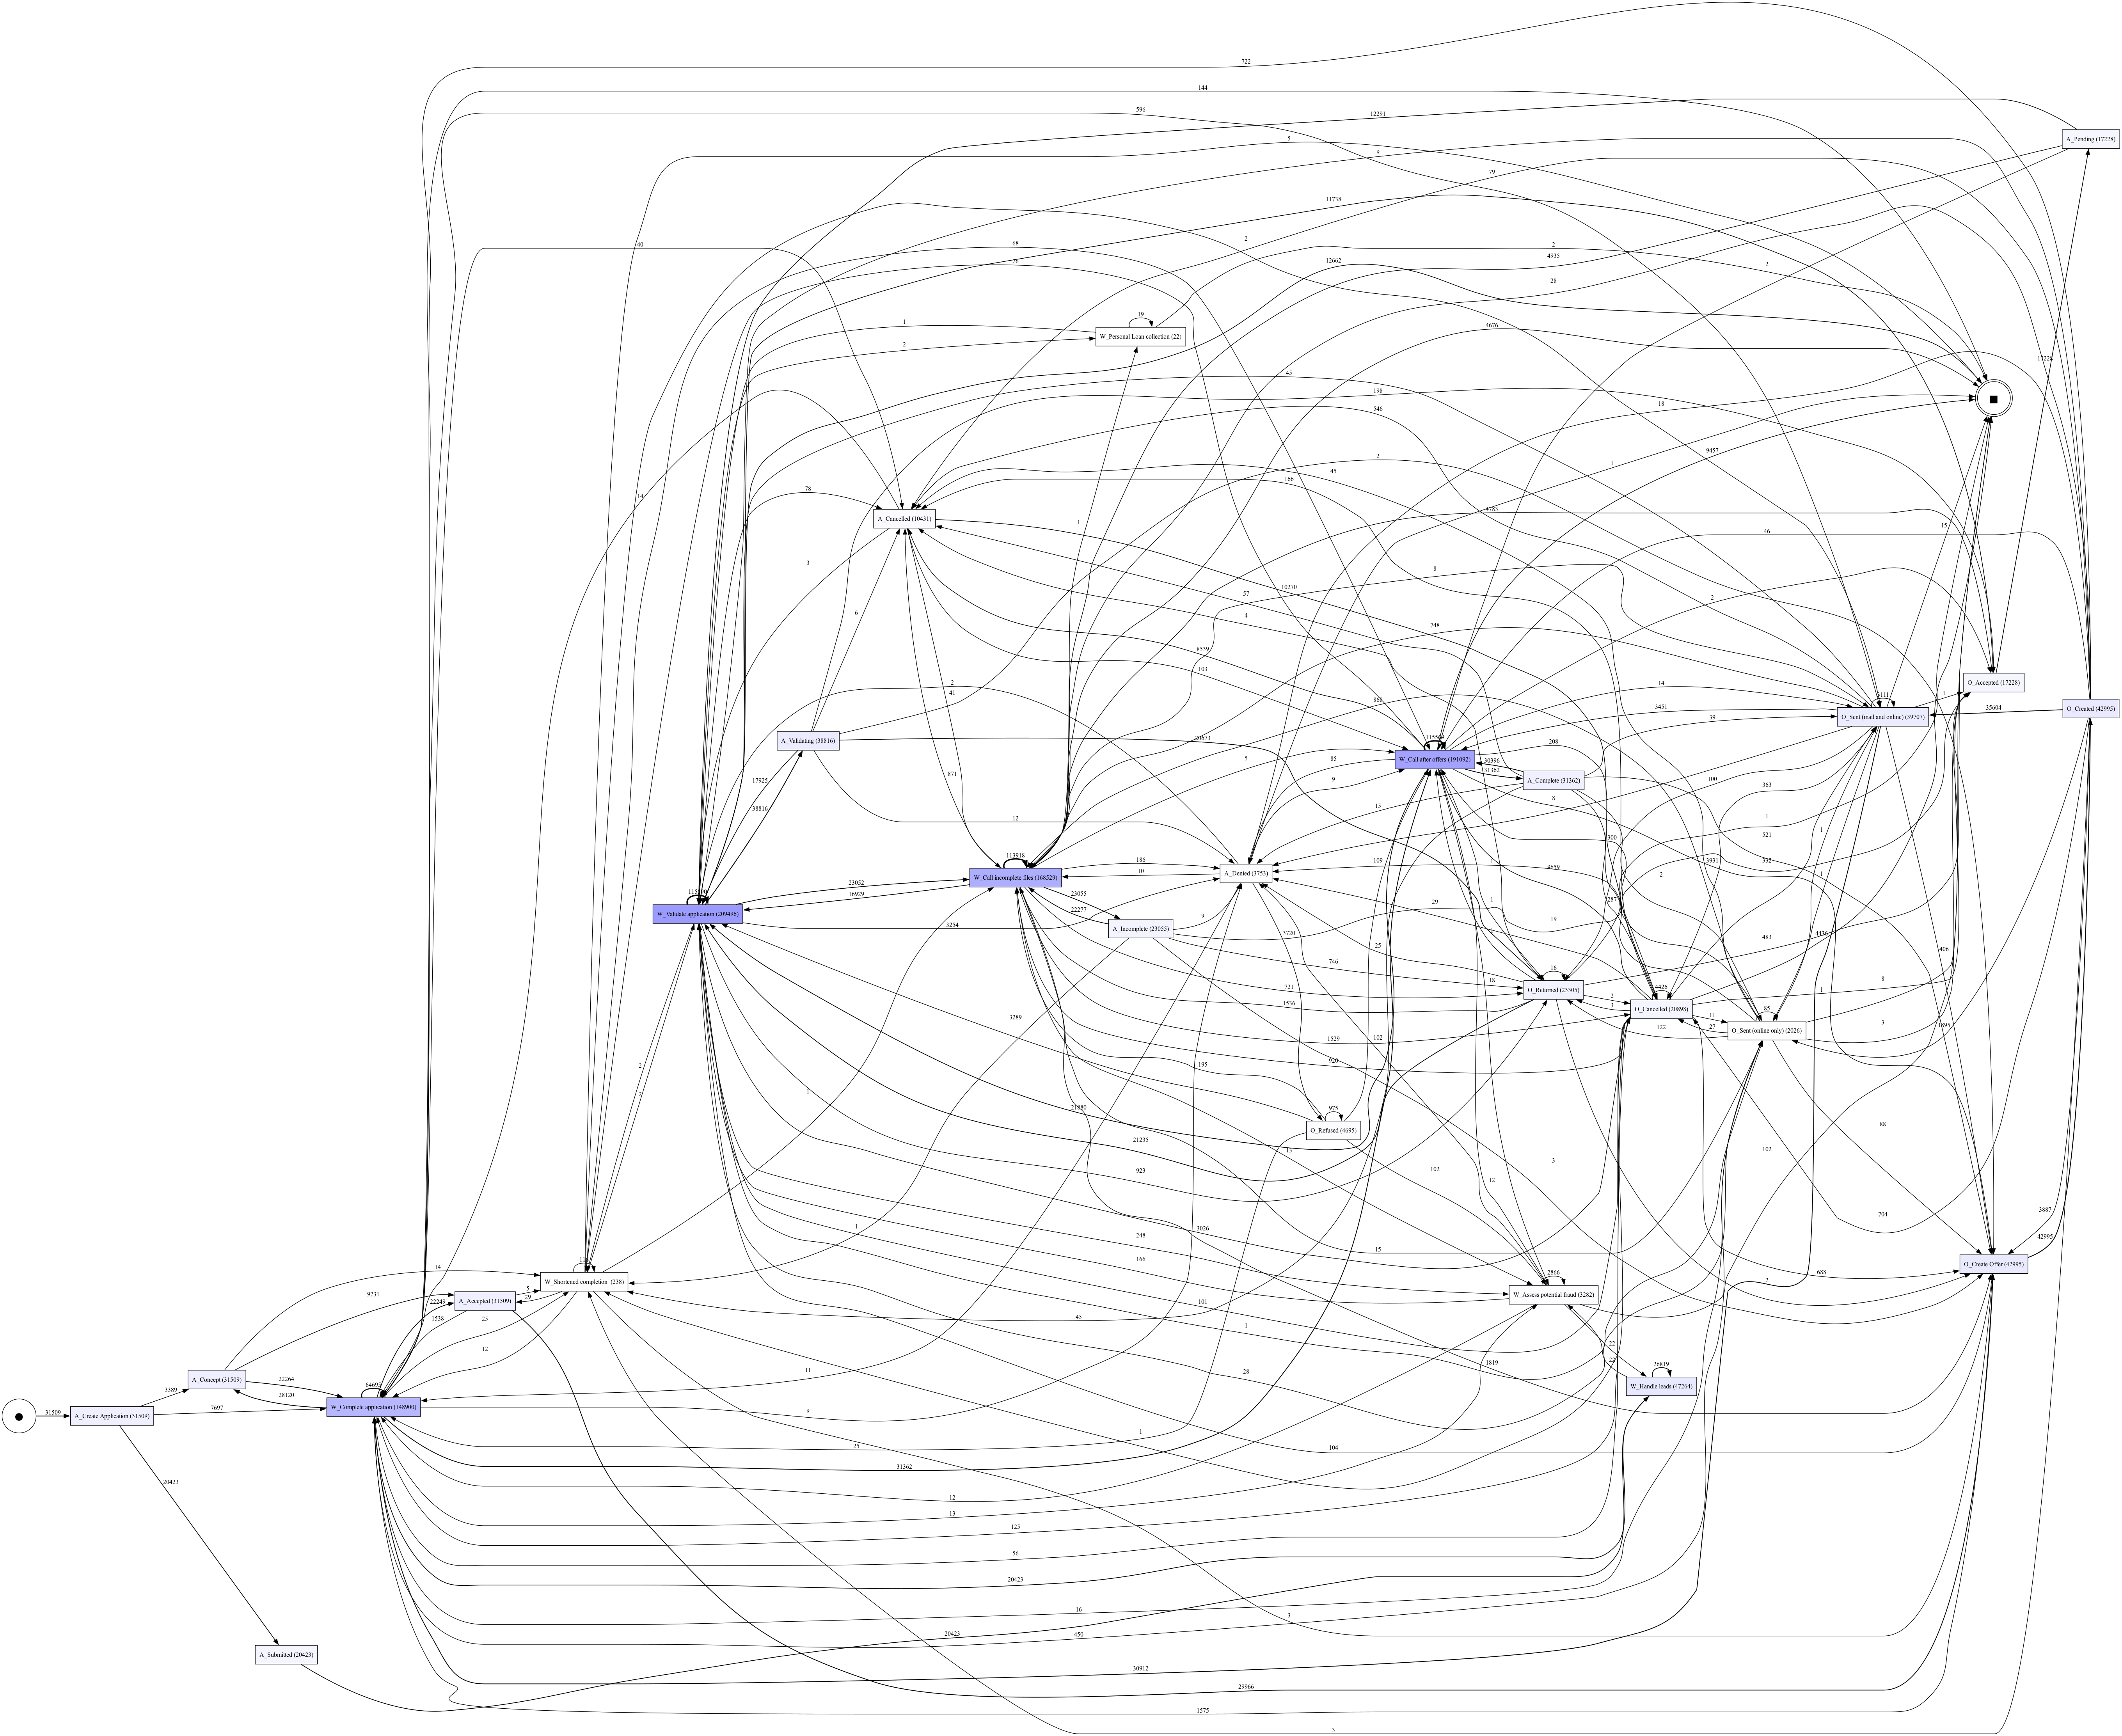

In [8]:
dfg, start_activities, end_activities = pm4py.discover_dfg(df)
pm4py.view_dfg(dfg, start_activities, end_activities)

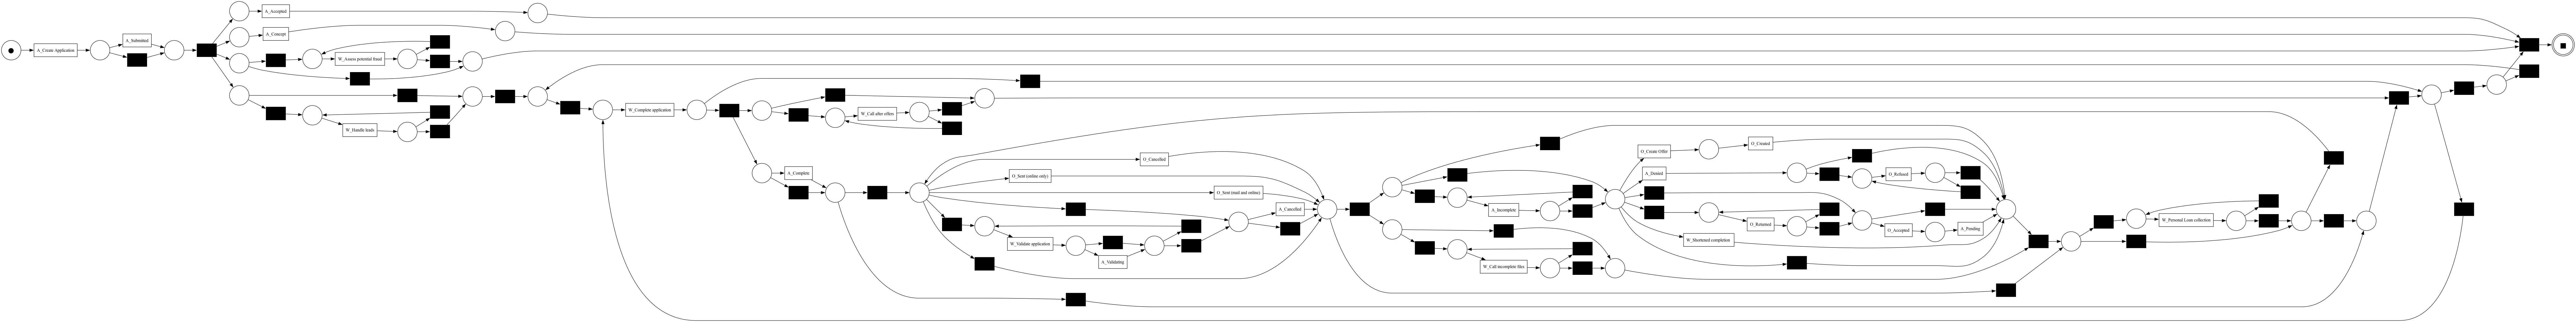

''

In [9]:
net2, im2, fm2 = pm4py.discover_petri_net_inductive(df)
pm4py.view_petri_net(net2, im2, fm2)

bpmn_im = pm4py.convert_to_bpmn(net2, im2, fm2) # pyright: ignore[reportArgumentType]

pm4py.write_bpmn(bpmn_im, '../output/inductive_miner.bpmn')
pm4py.save_vis_bpmn(bpmn_im, '../output/inductive_miner.png')


## Evaluation of initial process model

In [10]:
from evaluation import evaluate_model

In [11]:
net1, im1, fm1 = pm4py.convert_to_petri_net(dfg, start_activities, end_activities)

models = {
    'DFG': (net1, im1, fm1),
    'Inductive Miner': (net2, im2, fm2),
}

pd.DataFrame({name: evaluate_model(df, model) for name, model in models.items()}).round(3)

/Users/maximiliankaiser/tum/bp-pso/tum-bp-pso-process-mining/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
replaying log with TBR, completed traces :: 100%|██████████| 15930/15930 [00:49<00:00, 324.44it/s]


,DFG,Inductive Miner
Fitness,1.000,1.000
Perfect_Fit_Share,1.000,1.000
Precision,0.214,0.141
Generalization,0.767,0.948
Simplicity,0.402,0.628
Simplicity_NodeDegree,29.000,9.000
Simplicity_Depth,NaN,13.000
Silent_Share,0.063,0.701
